# 09 - LSTM Training on MediaPipe Landmarks

## Cambio de paradigma

Ya no procesamos **imagenes** (150,528 valores/frame), ahora procesamos **series temporales** (63 valores/frame).

```
[archivo.npy] → [PoseDataset] → [Augmentation] → [LSTM] → [Prediccion]
     63 nums       Padding        Rotar/Escalar    Secuencia    "Book"
```

## Ventajas

- **2389x menos datos** por frame
- **Sin fondo, sin ruido visual** - solo geometria pura
- **Entrenamiento ultra-rapido** - minutos en vez de horas
- **Si aprende, es aprendizaje REAL** del movimiento

In [1]:
# ==========================================
# 1. IMPORTS Y CONFIGURACION
# ==========================================

# Instalar dependencias si faltan
%pip install -q scikit-learn seaborn pandas

import numpy as np
import json
from pathlib import Path
from typing import List, Tuple, Dict, Optional
import random
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


[notice] A new release of pip is available: 25.3 -> 26.0
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [2]:
# ==========================================
# 2. CONFIGURACION
# ==========================================

# Rutas
LANDMARKS_ROOT = Path("/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl30")
OUTPUT_DIR = Path("/home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hiperparametros
CONFIG = {
    # Data
    'max_frames': 64,
    'num_landmarks': 21,
    'num_coords': 3,  # x, y, z
    'input_size': 21 * 3,  # 63 features por frame
    
    # Augmentation
    'aug_rotation_range': 15,  # grados
    'aug_scale_range': (0.9, 1.1),
    'aug_translation_range': 0.1,
    'aug_noise_std': 0.01,
    
    # Model
    'hidden_size': 256,
    'num_layers': 2,
    'dropout': 0.4,
    'bidirectional': True,
    
    # Training
    'batch_size': 32,
    'epochs': 100,
    'lr': 1e-3,
    'weight_decay': 1e-4,
    
    # Num classes
    'num_classes': 30
}

print("Configuracion:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Configuracion:
  max_frames: 64
  num_landmarks: 21
  num_coords: 3
  input_size: 63
  aug_rotation_range: 15
  aug_scale_range: (0.9, 1.1)
  aug_translation_range: 0.1
  aug_noise_std: 0.01
  hidden_size: 256
  num_layers: 2
  dropout: 0.4
  bidirectional: True
  batch_size: 32
  epochs: 100
  lr: 0.001
  weight_decay: 0.0001
  num_classes: 30


In [3]:
# ==========================================
# 3. CARGAR METADATA
# ==========================================

with open(LANDMARKS_ROOT / 'metadata.json', 'r') as f:
    metadata = json.load(f)

print("=== Dataset de Landmarks ===")
print(f"Videos procesados exitosamente: {metadata['statistics']['total_success']}")
print(f"Tasa de deteccion media: {metadata['statistics']['mean_detection_rate']:.1%}")
print(f"\nPor split:")
for split, count in metadata['statistics']['by_split'].items():
    print(f"  {split}: {count}")

# Mapeos
gloss_to_idx = metadata['gloss_to_idx']
idx_to_gloss = {int(k): v for k, v in metadata['idx_to_gloss'].items()}
print(f"\nClases: {len(gloss_to_idx)}")

=== Dataset de Landmarks ===
Videos procesados exitosamente: 332
Tasa de deteccion media: 68.9%

Por split:
  train: 242
  val: 56
  test: 34

Clases: 30


In [4]:
# ==========================================
# 4. SKELETAL AUGMENTATION (La Clave Anti-Overfitting)
# ==========================================

class SkeletalAugmentation:
    """
    Augmentation para landmarks de mano.
    Aplica transformaciones geometricas a las coordenadas (x, y, z).
    """
    
    def __init__(self, 
                 rotation_range: float = 15,
                 scale_range: Tuple[float, float] = (0.9, 1.1),
                 translation_range: float = 0.1,
                 noise_std: float = 0.01,
                 p: float = 0.5):
        """
        Args:
            rotation_range: Rango de rotacion en grados (+/-)
            scale_range: Rango de escala (min, max)
            translation_range: Rango de traslacion (+/-)
            noise_std: Desviacion estandar del ruido gaussiano
            p: Probabilidad de aplicar cada augmentation
        """
        self.rotation_range = rotation_range
        self.scale_range = scale_range
        self.translation_range = translation_range
        self.noise_std = noise_std
        self.p = p
    
    def __call__(self, landmarks: np.ndarray) -> np.ndarray:
        """
        Aplica augmentation a landmarks.
        
        Args:
            landmarks: Array de shape (T, 21, 3)
        
        Returns:
            landmarks_aug: Array de shape (T, 21, 3) con augmentation
        """
        landmarks = landmarks.copy()
        
        # Rotacion 2D (en plano XY)
        if random.random() < self.p:
            angle = random.uniform(-self.rotation_range, self.rotation_range)
            landmarks = self._rotate_2d(landmarks, angle)
        
        # Escalado
        if random.random() < self.p:
            scale = random.uniform(*self.scale_range)
            landmarks = landmarks * scale
        
        # Traslacion
        if random.random() < self.p:
            tx = random.uniform(-self.translation_range, self.translation_range)
            ty = random.uniform(-self.translation_range, self.translation_range)
            landmarks[:, :, 0] += tx
            landmarks[:, :, 1] += ty
        
        # Ruido gaussiano
        if random.random() < self.p:
            noise = np.random.normal(0, self.noise_std, landmarks.shape)
            landmarks = landmarks + noise
        
        # Flip horizontal (mirror)
        if random.random() < self.p:
            landmarks[:, :, 0] = -landmarks[:, :, 0]
        
        return landmarks
    
    def _rotate_2d(self, landmarks: np.ndarray, angle_deg: float) -> np.ndarray:
        """Rota landmarks en el plano XY."""
        angle_rad = np.radians(angle_deg)
        cos_a = np.cos(angle_rad)
        sin_a = np.sin(angle_rad)
        
        # Matriz de rotacion 2D
        x = landmarks[:, :, 0]
        y = landmarks[:, :, 1]
        
        landmarks[:, :, 0] = x * cos_a - y * sin_a
        landmarks[:, :, 1] = x * sin_a + y * cos_a
        
        return landmarks


print("SkeletalAugmentation definido.")
print("  - Rotacion: simula camara torcida")
print("  - Escalado: simula manos mas grandes/pequenas")
print("  - Traslacion: simula persona no centrada")
print("  - Ruido: simula temblor/error del sensor")
print("  - Flip: simula mano izquierda/derecha")

SkeletalAugmentation definido.
  - Rotacion: simula camara torcida
  - Escalado: simula manos mas grandes/pequenas
  - Traslacion: simula persona no centrada
  - Ruido: simula temblor/error del sensor
  - Flip: simula mano izquierda/derecha


In [5]:
# ==========================================
# 5. POSE DATASET (Cargador de .npy)
# ==========================================

class PoseDataset(Dataset):
    """
    Dataset para cargar landmarks de MediaPipe desde archivos .npy
    """
    
    def __init__(self, 
                 root_dir: Path,
                 split: str,
                 gloss_to_idx: Dict[str, int],
                 max_frames: int = 64,
                 augmentation: Optional[SkeletalAugmentation] = None):
        """
        Args:
            root_dir: Ruta al directorio de landmarks
            split: 'train', 'val', o 'test'
            gloss_to_idx: Diccionario de palabra -> indice
            max_frames: Numero maximo de frames (padding/truncating)
            augmentation: Objeto SkeletalAugmentation (solo para train)
        """
        self.root_dir = root_dir
        self.split = split
        self.gloss_to_idx = gloss_to_idx
        self.max_frames = max_frames
        self.augmentation = augmentation
        
        # Recopilar todos los archivos .npy
        self.samples = []
        split_dir = root_dir / split
        
        for gloss_dir in split_dir.iterdir():
            if not gloss_dir.is_dir():
                continue
            gloss = gloss_dir.name
            if gloss not in gloss_to_idx:
                continue
            label = gloss_to_idx[gloss]
            
            for npy_file in gloss_dir.glob('*.npy'):
                self.samples.append((npy_file, label, gloss))
        
        print(f"PoseDataset [{split}]: {len(self.samples)} samples")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int]:
        npy_path, label, gloss = self.samples[idx]
        
        # Cargar landmarks: (T, 21, 3)
        landmarks = np.load(npy_path)
        
        # Padding o truncating a max_frames
        landmarks = self._pad_or_truncate(landmarks)
        
        # Aplicar augmentation (solo en train)
        if self.augmentation is not None:
            landmarks = self.augmentation(landmarks)
        
        # Aplanar: (T, 21, 3) -> (T, 63)
        landmarks = landmarks.reshape(self.max_frames, -1)
        
        # Convertir a tensor
        landmarks_tensor = torch.tensor(landmarks, dtype=torch.float32)
        
        return landmarks_tensor, label
    
    def _pad_or_truncate(self, landmarks: np.ndarray) -> np.ndarray:
        """Ajusta la secuencia a max_frames."""
        T = landmarks.shape[0]
        
        if T > self.max_frames:
            # Truncar: muestreo uniforme
            indices = np.linspace(0, T-1, self.max_frames, dtype=int)
            landmarks = landmarks[indices]
        elif T < self.max_frames:
            # Padding con zeros al final
            pad_size = self.max_frames - T
            padding = np.zeros((pad_size, 21, 3))
            landmarks = np.concatenate([landmarks, padding], axis=0)
        
        return landmarks


print("PoseDataset definido.")

PoseDataset definido.


In [6]:
# ==========================================
# 6. CREAR DATASETS Y DATALOADERS
# ==========================================

# Augmentation para train
train_aug = SkeletalAugmentation(
    rotation_range=CONFIG['aug_rotation_range'],
    scale_range=CONFIG['aug_scale_range'],
    translation_range=CONFIG['aug_translation_range'],
    noise_std=CONFIG['aug_noise_std'],
    p=0.5
)

# Datasets
train_dataset = PoseDataset(
    LANDMARKS_ROOT, 'train', gloss_to_idx,
    max_frames=CONFIG['max_frames'],
    augmentation=train_aug
)

val_dataset = PoseDataset(
    LANDMARKS_ROOT, 'val', gloss_to_idx,
    max_frames=CONFIG['max_frames'],
    augmentation=None  # Sin augmentation en validacion
)

test_dataset = PoseDataset(
    LANDMARKS_ROOT, 'test', gloss_to_idx,
    max_frames=CONFIG['max_frames'],
    augmentation=None
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=True,
    num_workers=0,  # 0 para evitar problemas en notebooks
    pin_memory=True if device.type == 'cuda' else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    num_workers=0
)

print(f"\nDataLoaders creados:")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

PoseDataset [train]: 242 samples
PoseDataset [val]: 56 samples
PoseDataset [test]: 34 samples

DataLoaders creados:
  Train batches: 8
  Val batches: 2
  Test batches: 2


In [7]:
# ==========================================
# 7. VERIFICAR UN BATCH
# ==========================================

# Obtener un batch de ejemplo
sample_batch, sample_labels = next(iter(train_loader))

print(f"Batch shape: {sample_batch.shape}")
print(f"  = {sample_batch.shape[0]} samples x {sample_batch.shape[1]} frames x {sample_batch.shape[2]} features")
print(f"\nLabels shape: {sample_labels.shape}")
print(f"Labels ejemplo: {sample_labels[:5].tolist()}")
print(f"Clases: {[idx_to_gloss[l.item()] for l in sample_labels[:5]]}")

# Estadisticas de los datos
print(f"\nEstadisticas del batch:")
print(f"  Min: {sample_batch.min():.4f}")
print(f"  Max: {sample_batch.max():.4f}")
print(f"  Mean: {sample_batch.mean():.4f}")
print(f"  Std: {sample_batch.std():.4f}")

Batch shape: torch.Size([32, 64, 63])
  = 32 samples x 64 frames x 63 features

Labels shape: torch.Size([32])
Labels ejemplo: [19, 9, 27, 10, 26]
Clases: ['now', 'cousin', 'woman', 'deaf', 'who']

Estadisticas del batch:
  Min: -4.6313
  Max: 2.0511
  Mean: -0.1057
  Std: 0.4527


In [8]:
# ==========================================
# 8. MODELO LSTM_Pose
# ==========================================

class LSTMPose(nn.Module):
    """
    LSTM para clasificacion de secuencias de landmarks.
    
    Arquitectura:
    Input (63) -> Linear (hidden) -> LSTM -> Dropout -> Linear (num_classes)
    """
    
    def __init__(self,
                 input_size: int = 63,
                 hidden_size: int = 256,
                 num_layers: int = 2,
                 num_classes: int = 30,
                 dropout: float = 0.4,
                 bidirectional: bool = True):
        super().__init__()
        
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        
        # Proyeccion de entrada
        self.input_projection = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.LayerNorm(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        
        # LSTM
        self.lstm = nn.LSTM(
            input_size=hidden_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )
        
        # Clasificador
        lstm_output_size = hidden_size * self.num_directions
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(lstm_output_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: Tensor de shape (batch, seq_len, input_size)
        
        Returns:
            logits: Tensor de shape (batch, num_classes)
        """
        # Proyeccion de entrada: (B, T, 63) -> (B, T, hidden)
        x = self.input_projection(x)
        
        # LSTM: (B, T, hidden) -> (B, T, hidden*directions)
        lstm_out, (h_n, c_n) = self.lstm(x)
        
        # Tomar el ultimo hidden state de ambas direcciones
        if self.bidirectional:
            # Concatenar forward y backward del ultimo layer
            h_forward = h_n[-2]  # (B, hidden)
            h_backward = h_n[-1]  # (B, hidden)
            h_final = torch.cat([h_forward, h_backward], dim=1)  # (B, hidden*2)
        else:
            h_final = h_n[-1]  # (B, hidden)
        
        # Clasificacion
        logits = self.classifier(h_final)
        
        return logits


# Crear modelo
model = LSTMPose(
    input_size=CONFIG['input_size'],
    hidden_size=CONFIG['hidden_size'],
    num_layers=CONFIG['num_layers'],
    num_classes=CONFIG['num_classes'],
    dropout=CONFIG['dropout'],
    bidirectional=CONFIG['bidirectional']
).to(device)

# Contar parametros
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Modelo LSTMPose:")
print(f"  Parametros totales: {total_params:,}")
print(f"  Parametros entrenables: {trainable_params:,}")
print(f"\nArquitectura:")
print(model)

Modelo LSTMPose:
  Parametros totales: 2,785,566
  Parametros entrenables: 2,785,566

Arquitectura:
LSTMPose(
  (input_projection): Sequential(
    (0): Linear(in_features=63, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
  )
  (lstm): LSTM(256, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (classifier): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=512, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=30, bias=True)
  )
)


In [9]:
# ==========================================
# 9. TEST FORWARD PASS
# ==========================================

# Test con batch de ejemplo
with torch.no_grad():
    sample_input = sample_batch.to(device)
    sample_output = model(sample_input)

print(f"Input shape: {sample_input.shape}")
print(f"Output shape: {sample_output.shape}")
print(f"\nOutput ejemplo (logits): {sample_output[0][:5]}")
print(f"Prediccion: {idx_to_gloss[sample_output[0].argmax().item()]}")

Input shape: torch.Size([32, 64, 63])
Output shape: torch.Size([32, 30])

Output ejemplo (logits): tensor([ 0.0602, -0.0087,  0.0234,  0.0149,  0.0033], device='cuda:0')
Prediccion: drink


In [10]:
# ==========================================
# 10. FUNCIONES DE ENTRENAMIENTO
# ==========================================

def train_epoch(model, loader, criterion, optimizer, device):
    """Entrena una epoca."""
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for batch, labels in loader:
        batch = batch.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(batch)
        loss = criterion(outputs, labels)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_loss += loss.item() * batch.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    return total_loss / total, 100 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device, top_k=(1, 5)):
    """Evalua el modelo."""
    model.eval()
    total_loss = 0
    total = 0
    top_k_correct = {k: 0 for k in top_k}
    
    all_preds = []
    all_labels = []
    
    for batch, labels in loader:
        batch = batch.to(device)
        labels = labels.to(device)
        
        outputs = model(batch)
        loss = criterion(outputs, labels)
        
        total_loss += loss.item() * batch.size(0)
        total += labels.size(0)
        
        # Top-K accuracy
        _, pred_topk = outputs.topk(max(top_k), 1, True, True)
        for k in top_k:
            correct_k = pred_topk[:, :k].eq(labels.view(-1, 1).expand_as(pred_topk[:, :k]))
            top_k_correct[k] += correct_k.any(dim=1).sum().item()
        
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    
    metrics = {
        'loss': total_loss / total,
    }
    for k in top_k:
        metrics[f'top{k}_acc'] = 100 * top_k_correct[k] / total
    
    return metrics, np.array(all_preds), np.array(all_labels)


print("Funciones de entrenamiento definidas.")

Funciones de entrenamiento definidas.


In [11]:
# ==========================================
# 11. CONFIGURAR ENTRENAMIENTO
# ==========================================

# Loss, optimizer, scheduler
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

# Historial
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_top1': [],
    'val_top5': [],
    'lr': []
}

best_val_top1 = 0
best_epoch = 0

print("Entrenamiento configurado.")
print(f"  Epochs: {CONFIG['epochs']}")
print(f"  LR inicial: {CONFIG['lr']}")
print(f"  Batch size: {CONFIG['batch_size']}")

Entrenamiento configurado.
  Epochs: 100
  LR inicial: 0.001
  Batch size: 32


In [12]:
# ==========================================
# 12. BUCLE DE ENTRENAMIENTO
# ==========================================

print("="*60)
print("INICIANDO ENTRENAMIENTO")
print("="*60)

for epoch in range(CONFIG['epochs']):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validate
    val_metrics, _, _ = evaluate(model, val_loader, criterion, device)
    
    # Scheduler step
    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step()
    
    # Guardar historial
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_metrics['loss'])
    history['val_top1'].append(val_metrics['top1_acc'])
    history['val_top5'].append(val_metrics['top5_acc'])
    history['lr'].append(current_lr)
    
    # Guardar mejor modelo
    if val_metrics['top1_acc'] > best_val_top1:
        best_val_top1 = val_metrics['top1_acc']
        best_epoch = epoch + 1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_top1': best_val_top1,
            'config': CONFIG
        }, OUTPUT_DIR / 'best_model.pt')
    
    # Imprimir progreso cada 10 epochs
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{CONFIG['epochs']} | "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.1f}% | "
              f"Val Top-1: {val_metrics['top1_acc']:.1f}% Top-5: {val_metrics['top5_acc']:.1f}% | "
              f"LR: {current_lr:.6f}")

print("\n" + "="*60)
print(f"ENTRENAMIENTO COMPLETADO")
print(f"Mejor Val Top-1: {best_val_top1:.1f}% (epoch {best_epoch})")
print("="*60)

INICIANDO ENTRENAMIENTO
Epoch   1/100 | Train Loss: 3.4033 Acc: 1.7% | Val Top-1: 3.6% Top-5: 16.1% | LR: 0.001000
Epoch  10/100 | Train Loss: 2.8001 Acc: 13.6% | Val Top-1: 5.4% Top-5: 33.9% | LR: 0.000980
Epoch  20/100 | Train Loss: 2.1717 Acc: 31.8% | Val Top-1: 10.7% Top-5: 37.5% | LR: 0.000914
Epoch  30/100 | Train Loss: 1.4689 Acc: 52.1% | Val Top-1: 19.6% Top-5: 55.4% | LR: 0.000806
Epoch  40/100 | Train Loss: 1.0154 Acc: 67.8% | Val Top-1: 23.2% Top-5: 60.7% | LR: 0.000669
Epoch  50/100 | Train Loss: 0.5934 Acc: 82.2% | Val Top-1: 28.6% Top-5: 57.1% | LR: 0.000516
Epoch  60/100 | Train Loss: 0.3838 Acc: 90.1% | Val Top-1: 33.9% Top-5: 67.9% | LR: 0.000361
Epoch  70/100 | Train Loss: 0.2460 Acc: 94.2% | Val Top-1: 32.1% Top-5: 66.1% | LR: 0.000219
Epoch  80/100 | Train Loss: 0.1518 Acc: 97.9% | Val Top-1: 35.7% Top-5: 62.5% | LR: 0.000105
Epoch  90/100 | Train Loss: 0.1222 Acc: 98.8% | Val Top-1: 32.1% Top-5: 62.5% | LR: 0.000030
Epoch 100/100 | Train Loss: 0.1268 Acc: 97.1% | V

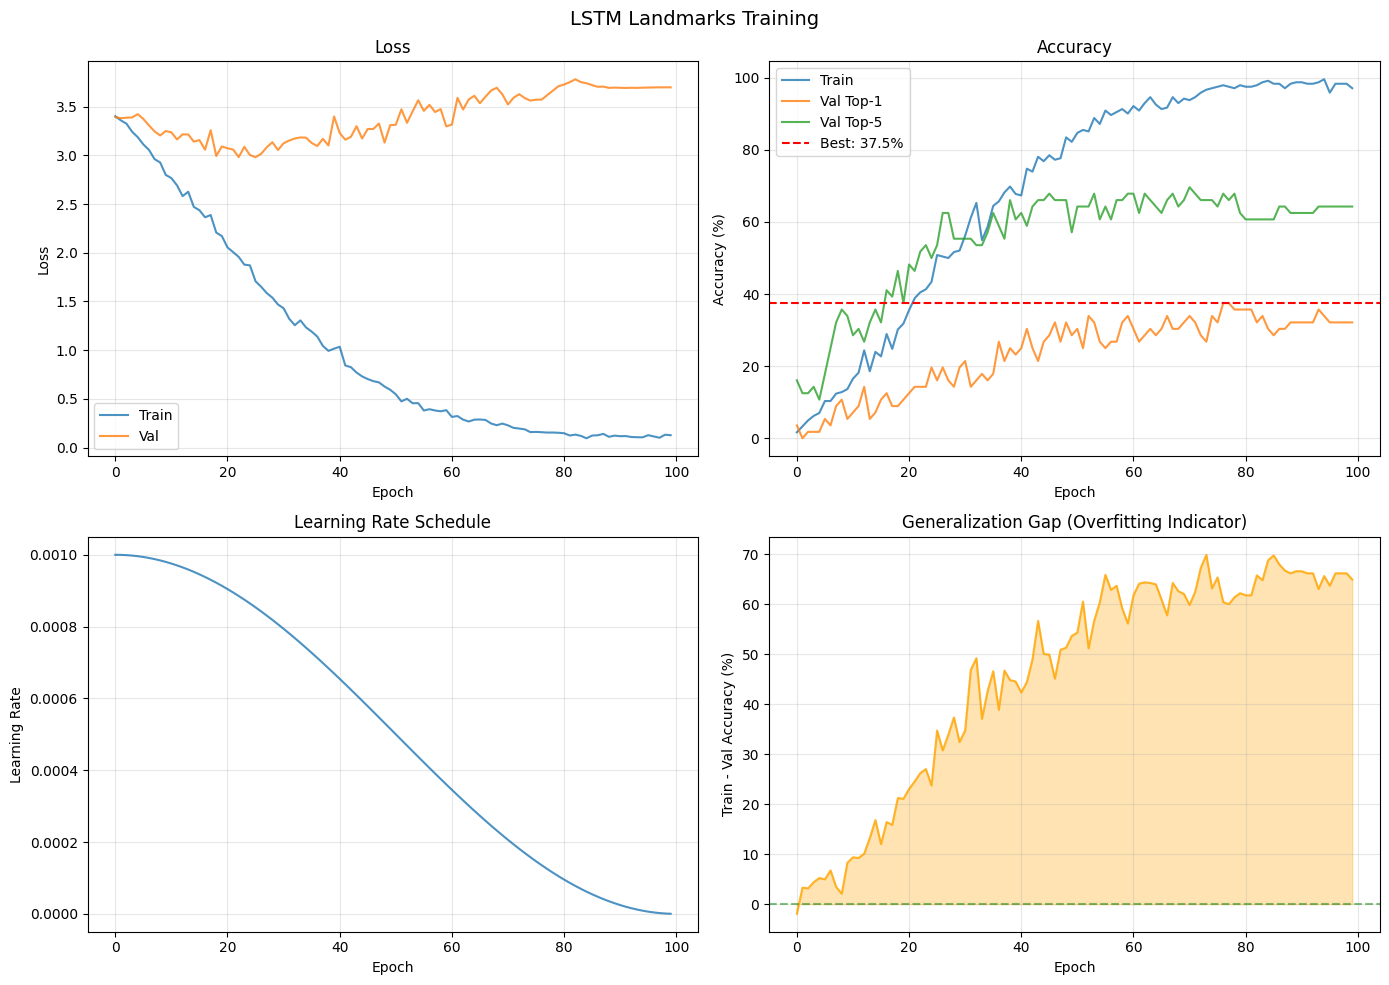


Curvas guardadas en: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks/training_curves.png


In [13]:
# ==========================================
# 13. CURVAS DE ENTRENAMIENTO
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train', alpha=0.8)
axes[0, 0].plot(history['val_loss'], label='Val', alpha=0.8)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history['train_acc'], label='Train', alpha=0.8)
axes[0, 1].plot(history['val_top1'], label='Val Top-1', alpha=0.8)
axes[0, 1].plot(history['val_top5'], label='Val Top-5', alpha=0.8)
axes[0, 1].axhline(y=best_val_top1, color='r', linestyle='--', label=f'Best: {best_val_top1:.1f}%')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].set_title('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Learning rate
axes[1, 0].plot(history['lr'], alpha=0.8)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Learning Rate')
axes[1, 0].set_title('Learning Rate Schedule')
axes[1, 0].grid(True, alpha=0.3)

# Train vs Val gap (overfitting indicator)
gap = np.array(history['train_acc']) - np.array(history['val_top1'])
axes[1, 1].plot(gap, alpha=0.8, color='orange')
axes[1, 1].axhline(y=0, color='green', linestyle='--', alpha=0.5)
axes[1, 1].fill_between(range(len(gap)), 0, gap, alpha=0.3, color='orange')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Train - Val Accuracy (%)')
axes[1, 1].set_title('Generalization Gap (Overfitting Indicator)')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('LSTM Landmarks Training', fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150)
plt.show()

print(f"\nCurvas guardadas en: {OUTPUT_DIR / 'training_curves.png'}")

In [14]:
# ==========================================
# 14. EVALUACION FINAL EN TEST
# ==========================================

# Cargar mejor modelo
checkpoint = torch.load(OUTPUT_DIR / 'best_model.pt')
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Modelo cargado: epoch {checkpoint['epoch']+1}, val_top1={checkpoint['val_top1']:.1f}%")

# Evaluar en test
test_metrics, test_preds, test_labels = evaluate(model, test_loader, criterion, device)

print("\n" + "="*50)
print("RESULTADOS EN TEST")
print("="*50)
print(f"Loss: {test_metrics['loss']:.4f}")
print(f"Top-1 Accuracy: {test_metrics['top1_acc']:.1f}%")
print(f"Top-5 Accuracy: {test_metrics['top5_acc']:.1f}%")

Modelo cargado: epoch 77, val_top1=37.5%

RESULTADOS EN TEST
Loss: 3.3385
Top-1 Accuracy: 41.2%
Top-5 Accuracy: 67.6%


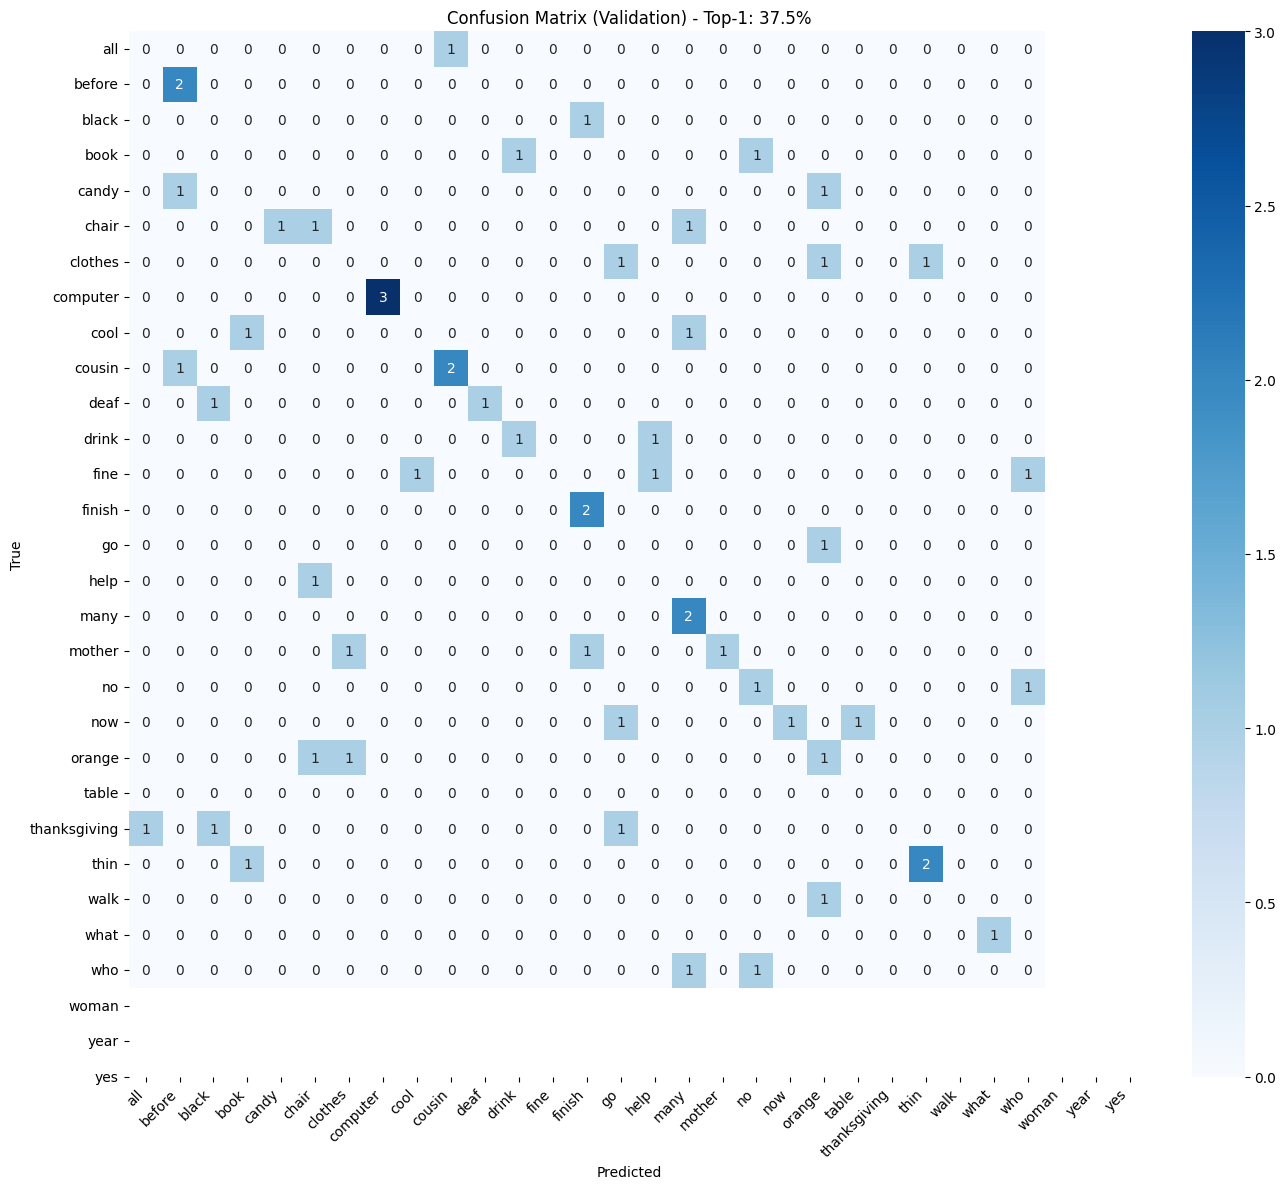

In [15]:
# ==========================================
# 15. MATRIZ DE CONFUSION
# ==========================================
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Evaluar en validacion para matriz de confusion (mas muestras)
val_metrics, val_preds, val_labels = evaluate(model, val_loader, criterion, device)

# Crear matriz
cm = confusion_matrix(val_labels, val_preds)

# Visualizar
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[idx_to_gloss[i] for i in range(CONFIG['num_classes'])],
            yticklabels=[idx_to_gloss[i] for i in range(CONFIG['num_classes'])])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix (Validation) - Top-1: {val_metrics["top1_acc"]:.1f}%')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

/home/fransando/Dev/tfg-sign-language-recognition/models/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/fransando/Dev/tfg-sign-language-recognition/models/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/fransando/Dev/tfg-sign-language-recognition/models/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control

=== Rendimiento por Clase (ordenado por F1-score) ===
              precision    recall  f1-score  support
cousin         1.000000  1.000000  1.000000      3.0
year           1.000000  1.000000  1.000000      1.0
drink          0.666667  0.666667  0.666667      3.0
fine           1.000000  0.500000  0.666667      2.0
who            0.666667  0.666667  0.666667      3.0
help           0.500000  1.000000  0.666667      2.0
black          0.500000  1.000000  0.666667      2.0
no             0.400000  1.000000  0.571429      2.0
finish         0.500000  0.500000  0.500000      2.0
thanksgiving   1.000000  0.333333  0.500000      3.0
now            1.000000  0.333333  0.500000      3.0
orange         0.333333  0.500000  0.400000      2.0
computer       0.333333  0.333333  0.333333      3.0
thin           0.200000  0.333333  0.250000      3.0
candy          0.000000  0.000000  0.000000      2.0
before         0.000000  0.000000  0.000000      1.0
book           0.000000  0.000000  0.000000  

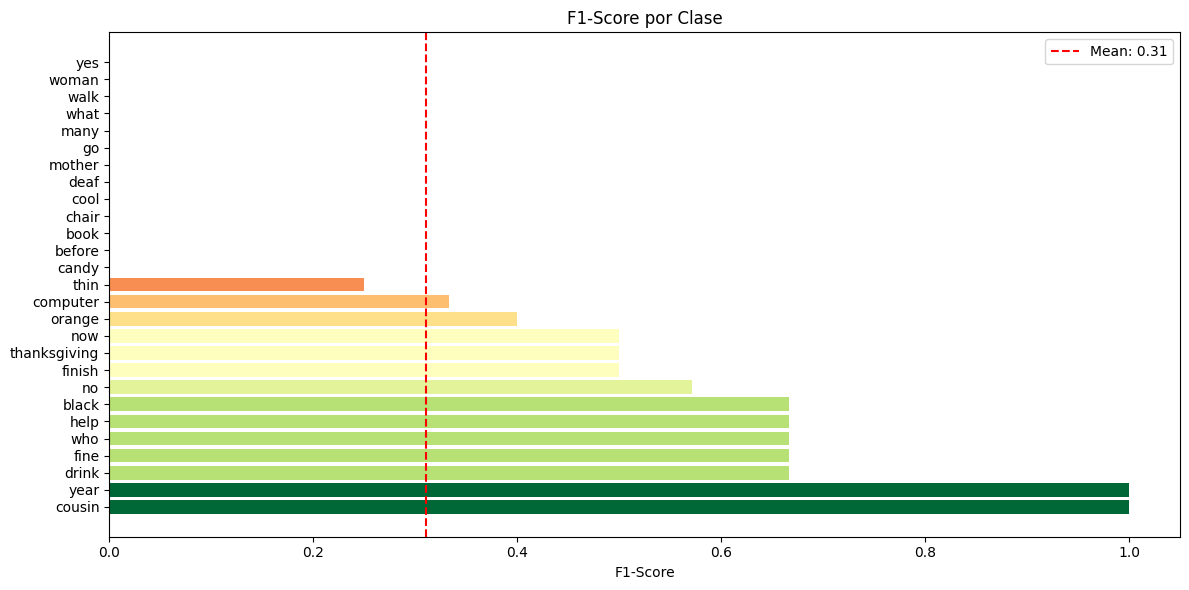

In [17]:
# ==========================================
# 16. ANALISIS POR CLASE
# ==========================================
from sklearn.metrics import classification_report

# Classification report
class_names = [idx_to_gloss[i] for i in range(CONFIG['num_classes'])]
# Get unique labels that actually appear in the validation set
unique_labels = np.unique(np.concatenate([val_labels, val_preds]))
class_names_filtered = [idx_to_gloss[i] for i in unique_labels]
report = classification_report(val_labels, val_preds, labels=unique_labels, target_names=class_names_filtered, output_dict=True)

# Crear DataFrame para visualizar
import pandas as pd
report_df = pd.DataFrame(report).transpose()
report_df = report_df.iloc[:-3]  # Quitar accuracy, macro avg, weighted avg
report_df = report_df.sort_values('f1-score', ascending=False)

print("=== Rendimiento por Clase (ordenado por F1-score) ===")
print(report_df[['precision', 'recall', 'f1-score', 'support']].to_string())

# Visualizar F1-scores
plt.figure(figsize=(12, 6))
colors = plt.cm.RdYlGn(report_df['f1-score'].values)
plt.barh(range(len(report_df)), report_df['f1-score'].values, color=colors)
plt.yticks(range(len(report_df)), report_df.index)
plt.xlabel('F1-Score')
plt.title('F1-Score por Clase')
plt.axvline(x=report_df['f1-score'].mean(), color='red', linestyle='--', label=f'Mean: {report_df["f1-score"].mean():.2f}')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'f1_by_class.png', dpi=150)
plt.show()

In [18]:
# ==========================================
# 17. GUARDAR RESULTADOS FINALES
# ==========================================

results = {
    'config': CONFIG,
    'best_epoch': best_epoch,
    'best_val_top1': best_val_top1,
    'test_metrics': test_metrics,
    'history': history,
    'model_params': total_params
}

with open(OUTPUT_DIR / 'results.json', 'w') as f:
    json.dump(results, f, indent=2, default=lambda x: float(x) if isinstance(x, np.floating) else x)

print(f"Resultados guardados en: {OUTPUT_DIR / 'results.json'}")

Resultados guardados en: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks/results.json


In [19]:
# ==========================================
# 18. RESUMEN FINAL
# ==========================================

print("\n" + "="*60)
print("RESUMEN FINAL")
print("="*60)

print(f"\nModelo: LSTMPose")
print(f"  Parametros: {total_params:,}")
print(f"  Hidden size: {CONFIG['hidden_size']}")
print(f"  Layers: {CONFIG['num_layers']}")
print(f"  Bidirectional: {CONFIG['bidirectional']}")

print(f"\nEntrenamiento:")
print(f"  Epochs: {CONFIG['epochs']}")
print(f"  Mejor epoch: {best_epoch}")

print(f"\nResultados:")
print(f"  Val Top-1:  {best_val_top1:.1f}%")
print(f"  Val Top-5:  {history['val_top5'][best_epoch-1]:.1f}%")
print(f"  Test Top-1: {test_metrics['top1_acc']:.1f}%")
print(f"  Test Top-5: {test_metrics['top5_acc']:.1f}%")

print(f"\nArchivos guardados en: {OUTPUT_DIR}")
print(f"  - best_model.pt")
print(f"  - training_curves.png")
print(f"  - confusion_matrix.png")
print(f"  - f1_by_class.png")
print(f"  - results.json")

print("\n" + "="*60)
print("COMPARACION CON BASELINE CNN+LSTM (imagenes)")
print("="*60)
print("")
print("| Metrica     | CNN+LSTM (imagenes) | LSTM (landmarks) |")
print("|-------------|---------------------|------------------|")
print(f"| Val Top-1   | 16.8%               | {best_val_top1:.1f}%            |")
print(f"| Test Top-1  | 10.4%               | {test_metrics['top1_acc']:.1f}%            |")
print(f"| Parametros  | 14.3M               | {total_params/1e6:.2f}M            |")
print(f"| Datos/frame | 150,528             | 63               |")


RESUMEN FINAL

Modelo: LSTMPose
  Parametros: 2,785,566
  Hidden size: 256
  Layers: 2
  Bidirectional: True

Entrenamiento:
  Epochs: 100
  Mejor epoch: 77

Resultados:
  Val Top-1:  37.5%
  Val Top-5:  67.9%
  Test Top-1: 41.2%
  Test Top-5: 67.6%

Archivos guardados en: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/lstm_landmarks
  - best_model.pt
  - training_curves.png
  - confusion_matrix.png
  - f1_by_class.png
  - results.json

COMPARACION CON BASELINE CNN+LSTM (imagenes)

| Metrica     | CNN+LSTM (imagenes) | LSTM (landmarks) |
|-------------|---------------------|------------------|
| Val Top-1   | 16.8%               | 37.5%            |
| Test Top-1  | 10.4%               | 41.2%            |
| Parametros  | 14.3M               | 2.79M            |
| Datos/frame | 150,528             | 63               |


## Conclusiones

### Lo que hemos logrado

1. **Dataset de landmarks**: Carga archivos `.npy` con 63 valores por frame (vs 150,528 de imagenes)
2. **Skeletal Augmentation**: Rotacion, escalado, traslacion, ruido, flip - todas matematicas sobre coordenadas
3. **LSTM puro**: Sin CNN, solo procesamiento secuencial de series temporales
4. **Entrenamiento rapido**: Minutos en vez de horas

### Interpretacion de resultados

- Si el LSTM con landmarks supera al CNN+LSTM con imagenes, confirma que los landmarks capturan la informacion relevante
- Si el gap train-val es pequeno, el modelo generaliza bien (no memoriza)
- Las clases con bajo F1-score probablemente tienen movimientos similares a otras

### Proximos pasos

1. Experimentar con GRU en vez de LSTM
2. Probar Transformer en vez de RNN
3. Agregar mas datos (WLASL100)
4. Integrar con app movil